# Xavior / glorot normalization  ---> Tanh  & Sigmoid
- sigmoid is less use in hidden layer 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/home/ipartzix/ML-Dataset/ushape.csv")

In [3]:
df.head()

,X,Y,class
0,0.031595,0.986988,0.0
1,2.115098,-0.046244,1.0
2,0.882490,-0.075756,0.0
3,-0.055144,-0.037332,1.0
4,0.829545,-0.539321,1.0


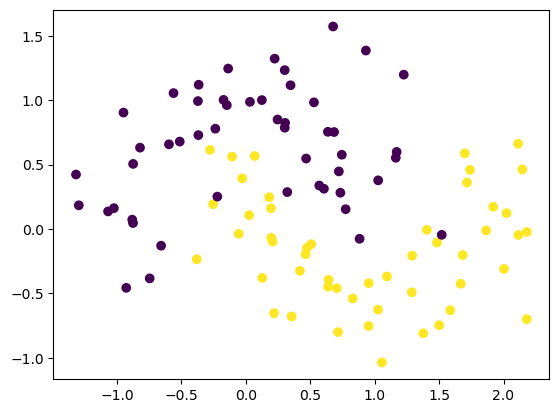

In [4]:
plt.scatter(df['X'],df['Y'],c=df['class'])

In [5]:
X = df.iloc[:,0:2].values
y = df.iloc[:,-1].values

In [6]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [7]:
model = Sequential()

model.add(Dense(10, activation="tanh", input_dim=2, kernel_initializer="glorot_normal"))
model.add(Dense(10, activation="tanh", kernel_initializer="glorot_normal"))
model.add(Dense(10, activation="tanh", kernel_initializer="glorot_normal"))
model.add(Dense(10, activation="tanh", kernel_initializer="glorot_normal"))
model.add(Dense(1, activation="sigmoid"))

model.summary()

/home/ipartzix/miniconda3/envs/MLE/lib/python3.10/site-packages/keras/src/layers/core/dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 371 (1.45 KB)

 Trainable params: 371 (1.45 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.get_weights()

[array([[ 0.37653023,  0.15436423, -0.30539215, -0.01392052, -0.6900841 ,
          0.5040806 , -0.41008353,  0.41453692,  0.758307  , -0.06900463],
        [ 0.11862411, -0.3508895 ,  0.07336762, -0.1599872 , -0.0873499 ,
          0.04531505, -0.20132254, -0.50270736,  0.01985147,  0.16641526]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[ 0.06859337, -0.14844611, -0.08810762, -0.0813828 , -0.16789205,
          0.3750805 , -0.03155818, -0.41302004,  0.26767787,  0.31785387],
        [ 0.08480482,  0.31353158,  0.04329397,  0.01468292, -0.4347373 ,
          0.46910277,  0.55072635, -0.39032403,  0.00476797,  0.06464038],
        [ 0.02278432, -0.3629795 , -0.21569827, -0.11024553, -0.40120634,
          0.12023321, -0.45645255, -0.29911235, -0.19932526,  0.15441343],
        [-0.05914695, -0.25339085, -0.39683712,  0.26108778, -0.02774115,
         -0.13817847, -0.23442778,  0.14925416, -0.38478938, -0.33743823],
        [ 0.06619

In [9]:
initial_weights = model.get_weights()

In [10]:
initial_weights[0] = np.random.randn(2,10)*np.sqrt(1/2)
initial_weights[1] = np.zeros(model.get_weights()[1].shape)
initial_weights[2] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[3] = np.zeros(model.get_weights()[3].shape)
initial_weights[4] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[5] = np.zeros(model.get_weights()[5].shape)
initial_weights[6] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[7] = np.zeros(model.get_weights()[7].shape)
initial_weights[8] = np.random.randn(10,1)*np.sqrt(1/10)
initial_weights[9] = np.zeros(model.get_weights()[9].shape)

In [11]:
model.set_weights(initial_weights)

In [12]:
model.get_weights()

[array([[-0.5159278 , -0.73177487, -0.37188593, -0.30157596, -0.62895215,
          0.51942617, -0.7008211 , -0.90300703, -0.8821333 ,  0.83214694],
        [-0.0694713 , -1.0511724 , -0.30285826, -0.37632418,  1.2717627 ,
         -0.26440793, -0.11757405, -1.396242  , -0.1429616 ,  0.5926384 ]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[-0.7441598 , -0.17008646,  0.06693438, -0.47737914, -0.08150982,
          0.12922974,  0.37379903, -0.05837246, -0.00468513, -0.0965943 ],
        [ 0.714486  ,  0.7019018 ,  0.10393324,  0.06915418,  0.18482682,
          0.5899432 , -0.4782928 ,  0.0093011 , -0.41308978,  0.0750268 ],
        [-0.15926015,  0.5519079 , -0.13933368, -0.05966886,  0.18993093,
         -0.31885839,  0.22475208, -0.00767228, -0.29729137,  0.4284572 ],
        [ 0.34326386, -0.00170343,  0.11799583,  0.47495487, -0.21649699,
          0.20108908,  0.15104619, -0.08470666, -0.21484885,  0.41772977],
        [-0.14621

In [13]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [14]:
history = model.fit(X,y,epochs=100,validation_split=0.2)

Epoch 1/100


3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 208ms/step - accuracy: 0.5000 - loss: 0.7242 - val_accuracy: 0.7000 - val_loss: 0.6452
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.5000 - loss: 0.7115 - val_accuracy: 0.7000 - val_loss: 0.6345
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.5250 - loss: 0.6975 - val_accuracy: 0.7000 - val_loss: 0.6240
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.5375 - loss: 0.6851 - val_accuracy: 0.7000 - val_loss: 0.6135
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.5625 - loss: 0.6740 - val_accuracy: 0.6500 - val_loss: 0.6039
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.5625 - loss: 0.6631 - val_accuracy: 0.7000 - val_loss: 0.5949
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.5625 - loss: 0.6523 - val_accuracy: 0.7000 - val_loss: 0.5863
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.6000 - loss: 0.6423 - val_accuracy: 0.7500 - val_loss: 0.5775
Epo

In [20]:
model.get_weights()

[array([[-0.42312524, -0.808086  , -0.424799  , -0.3695853 , -0.6122235 ,
          0.4812702 , -0.67669994, -0.88846153, -0.8070113 ,  0.88409984],
        [-0.10429118, -1.0118401 , -0.26375502, -0.4067447 ,  1.3783357 ,
         -0.4149201 , -0.17033266, -1.4159945 , -0.06368826,  0.687645  ]],
       dtype=float32),
 array([ 0.10748959, -0.17636968,  0.00226097, -0.02572481,  0.0664209 ,
        -0.05909922,  0.05259472,  0.25154978, -0.09056224, -0.13781625],
       dtype=float32),
 array([[-0.6967916 , -0.19067222,  0.0120369 , -0.4126751 , -0.12122051,
          0.20211183,  0.27754074, -0.0716228 , -0.09400874, -0.14181879],
        [ 0.6742155 ,  0.622877  ,  0.18765056,  0.18985914,  0.21511027,
          0.5264376 , -0.42194957,  0.09564836, -0.3629211 ,  0.05276125],
        [-0.18379183,  0.42795044, -0.08103085,  0.06249976,  0.2077049 ,
         -0.350305  ,  0.22955903,  0.08397402, -0.29521745,  0.37260902],
        [ 0.30063453, -0.11981338,  0.19113097,  0.5966096 , 

<Axes: >

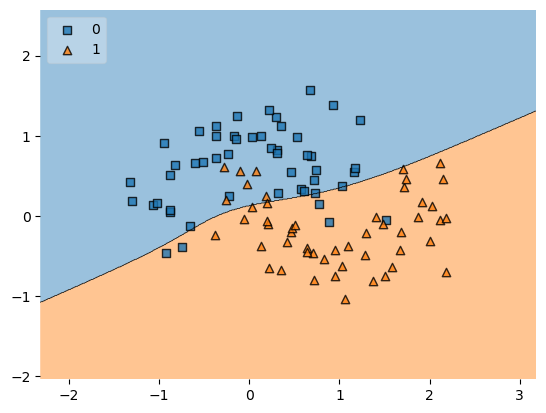

In [22]:
import numpy as np
from mlxtend.plotting import plot_decision_regions


class KerasClassifierWrapper:

    def __init__(self, model):
        self.model = model

    def predict(self, X):
        y_pred = self.model.predict(X, verbose=0)
        return (y_pred > 0.5).astype(int).ravel()


clf = KerasClassifierWrapper(model)

plot_decision_regions(
    X=np.array(X), y=np.array(y).astype(int).ravel(), clf=clf, legend=2
)

In [ ]:
(np.random.randn(10,10)*0.01).min()

-0.01538420487066039

In [ ]:
(np.random.randn(10,10)*0.01).max()

0.02825126600648443